# Labs: Image classification with Deep Learning A-C

In this Lab we will implement an image classification system with state-of-the-art deep learning methodology. In more concrete words, we will investigate how to use Neural Networks to recognize images containing cars and images not containing cars. This is thus a binary classification. 


The data set used is based on the [UIUC Image Database for Car Detection](http://cogcomp.cs.illinois.edu/Data/Car/) and contains:
* 917 training images (550 car and 367 non-car images)
* 302 test images (170 car images and 132 non-car images)
in both datasets cars are at roughly the same scale as in the training images (to make the task easier)


In the following Labs we will build a complete image classification pipeline and learn about the following topics:

**Lab A: Regular Deep Learning**
* Image Loading and Preprocessing
* Standardization of Data
* Fully Connected Neural Networks
* Plotting the Training Curve

**Lab B: Convolutional Neural Nets**
* Convolutional Neural Networks
* ReLU Activation
* Data Augmentation

**Lab C: Improving your network**
* Dropout
* Batch Normalization
* Tuning hyperparameters (Optional)
* Optimizing the network architecture (Optional)

# Lab A: Building our first neural network

## Pre-requisite

Start the Anaconda Navigator and install the <b>scikit-learn package</b>. We will need it later (i.e. we will need functions from the sklearn module which comes with the scikit-learn package

## Imports

In a first step we need to import all necessary packages. In our case this includes tensorflow/keras packages (our deep learning platform).

In [1]:
import os

import argparse
import csv
import datetime
import glob
import math
import sys
import time
import numpy as np

from PIL import Image

from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# if tensorflow version > 2 is used 
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Convolution2D, MaxPooling2D, Dense, Dropout, Activation, Flatten
from tensorflow.keras.layers import BatchNormalization

# if tensorflow version < 2 is used
#import keras
#from keras.models import Sequential
#from keras.layers import Convolution2D, MaxPooling2D, Dense, Dropout, Activation, Flatten
#from keras.layers.normalization import BatchNormalization


np.random.seed(42) # we initialize a random seed here to make the experiments repeatable with same results

If this cell runs without problems, it means that all libraries and functionality we need could be successfully installed and imported.

## Exercise 1

## Load the Images from Training Set

Now it is time to load the images from the training set. You can download the training (and test) data from eCampus (carData). Unpack it in a subfolder of this file. Adapt the relative path in the cell below and run the cell to see if you can "see" (i.e. count) the files.

In [2]:
#path = '../../data/car_classification/TrainImages'
# do not use BACKSLASH!
path = '../../data/car_classification/TrainImages'
files = glob.glob(os.path.join(path, '*.pgm'))
print("Found", len(files), "files!")


Found 917 files!


Now the first task is to read in the files. The files are grayscale images, i.e. single channel images. Each image can thus be represented by a simple two-dimensional matrix. Create two empty lisits (done already below) for the images and for the image names. 

Use a for loop and loop through all files in variable "files". Load the image with Image.open(). Transform it to a numpy array and append the numpy array to the list "images" (use images.append). 

Additionally, append the file names to list "image_names". Use os.path.basename to get the filename from the file URLs stored in variable "files".

As a result you have two lists: a list of images and a list of filenames. Print them out to see if that worked out and to see if they have the expected dimensions (use len() to get the number of elements of a list.


In [3]:
images = []
image_names = []

for f in files:
    images.append(np.array(Image.open(f)))
    image_names.append(os.path.basename(f))

print("Number of images:", len(images))
print("Number of image names:", len(image_names))

Number of images: 917
Number of image names: 917


Show an image from the list to see how the data looks like. Select an image from images for a given index i with "images[i]" and display it using matplotlib (plt.imshow()). Also print its filename as the figure title (plt.title()).

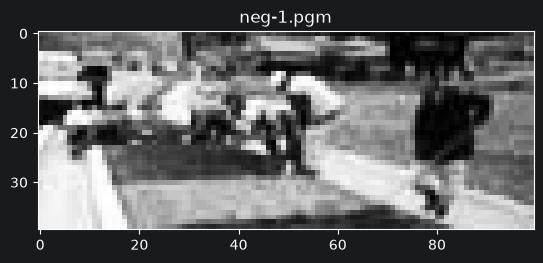

In [4]:
#Show a selected image to check
i=1

plt.imshow(images[i], cmap='gray')
plt.title(image_names[i])
plt.show()

Print which type of variable an image (e.g. images[0]) is. Use the function type() for this. It should be a numpy array. Print also the dimensions of this numpy array.

In [5]:
#todo: print type of variable that an image is stored in
#todo print dimensions of image    
print(type(images[0]))
print(images[0].shape)

<class 'numpy.ndarray'>
(40, 100)


Note: Color RGB images would have an additional dimension of depth = 3, e.g. (40, 100, 3)

## Make 1 big 3D array of list of images

Next we convert the list variable "images" into a 3D numpy array using the following simple line of code. Print the dimensions of this array.

In [6]:
# a list of many 40x100 images is made into 1 big array:

img_array = np.array(images, dtype=np.float32)
print(img_array.shape)

(917, 40, 100)


**Question**: What does each dimension represent?

**Write your answer here:**

The first dimension (917) is the number of images, the second (40) is the image height in pixels, and the third (100) is the image width in pixels.

## Create the Groundtruth labels based on filenames:

For every supervised learning task we need class labels, i.e. one label per input image. In our case labels are either 0 (negative, i.e. no car) or 1 (positive, car). The labels are encoded into the image names for simplicity. Images with cars start with "pos-" and images with no cars start with "neg-". 

Create a numeric list "classes" containing 1 for car images and 0 for non-car images.

Hint: you can retrieve (and match) the first characters in the filename with the .startswith() function. This means: if you have a string s containing the filename, you can call s.startswith('xy') to check if the string in s starts with 'xy' or not. This information you can use to check for positive / negative label, i.e. 1 or 0 

In [7]:
classes = []

for name in image_names:
    if name.startswith('pos'):
        classes.append(1)
    else:
        classes.append(0)

Print the first 400 values in variable classes

In [8]:
print(classes[:400])

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

Print the number of items per class. This can be done with this simple code below. "set" returns the unique values in list classes, i.e. 0 and 1. Then we use these values to loop over the set of labels and to count the corresponding entries in the list

In [9]:
print("Groundtruth Statistics:")

for v in set(classes):
    print("Class", v, ":", classes.count(v))

Groundtruth Statistics:
Class 0 : 367
Class 1 : 550


In a supervised classification experiment it is always interesting to see what a random classifier (without any "intelligence" would achieve. To simulate this, we can compute the so called "Zero-rule" probability of correct classification. That is: the best "stupid" guess we can make is to select always the label of the most frequent class in the dataset.

The baseline is then computed as: number_of_samples_of_most_frequent_class / total_number_of_samples_in_dataset. Example: if you have 90% men in a face dataset and 10% women, the zero rule probability is 0.9. This means: a classifier that always predicts a face to be a man will achieve 90%. A real classification result (classification accuracy) below 90% would mean that we do NOT generate any useful information with our classifier. Strictly spoken, only results above 90% count as being "good", i.e. better than the random baseline. 

Compute the baseline for our training set!

In [10]:
#todo: baseline = ...
baseline = max(classes.count(0), classes.count(1)) / len(classes)
print("Random baseline:", baseline)

Random baseline: 0.5997818974918212


## Standardization

<b>It is a good idea to standardize / normalize</b> the data before feeding it into a Neural Network. A neural network expects data that comes from the same statistical distribution. This means in our case the images should have the same mean and standard deviation. Standardization can remove unwanted variations in the data, e.g. brightness variations across the images. 

It is possible to train neural nets without standardization, especially if the images in the dataset are already normalized (like for example MNIST). However, for real problems, not normalizing makes it harder for your neural net to learn to recognize elements, because it needs to adjust for brightness *itself*, so it will take a longer time to converge. 

We use a global <b>Zero-mean Unit-variance standardization</b> which means we deduct the mean pixel value of all training images and divide them by the standard deviation of all pixel values.

Note: Here, we do this in a "global" manner, i.e. only one mean and std.dev. for the whole set of training images is computed. 

Note: In RGB images, standardization can be done e.g. for each colour channel individually; in other/non-image data sets, attribute-wise standardization should be applied.

Compute the mean of the entire 3D array of images (variable: img_array), note that this can be done with one call in numpy. You do not need any loops. Find out how that works.

Compute the standard deviation in the same way.

Now subtract the mean from all pixels of the images and then divide all images by the standard deviation. This can also be done with one single call (or two separate calls if you like). The numpy concept behind such operations is "broadcasting". Broadcasting means that an operation (e.g. subtraction of the mean value) is applied to all elements of a numpy array. 

Output the value range of the standardized array (use functions .min() and .max() from numpy)

**VERY IMPORTANT:** If you standardize the training data, you have to always also standardize the test data in the same way (with the mean and standard deviation of the training set)! Also, when using the model in production, the images also need to be always standardized. 

In [11]:
#mean = ...
#stddev = ...

# subtract mean and divide by stddev
# store result again in variable img_array (we don't need a copy, because we will only work with the standardized data)
mean = img_array.mean()
stddev = img_array.std()

img_array = (img_array - mean) / stddev

print("Min:", img_array.min())
print("Max:", img_array.max())

Min: -1.7452136
Max: 1.69139


## Exercise 2

## Defining a fully connected neural network, i.e. a multi-layer perceptron (MLP)

Next we will define a regular neural net: A "multi-layer perceptron" (actually a multi-layer sigmoid neuron network). Such networks exist of several fully connected layers (called also "Dense" layers in our deep learning framework Keras).

For a fully connected neural network, the x and y axis of an image do not play a role at all. All pixels are considered as a completely individual input to the neural network. Therefore the 2D image arrays have to be flattened to a vector.

In [12]:
#  flatten images to vectors

# TODO: use the .reshape() function on the variable img_array to 
# reshape the 3D array to a 2D array. The 2D array should have as 
# many rows as there are images (917) and as many columns as there are
# pixels: 4000

#images_flat = ...
images_flat = img_array.reshape(img_array.shape[0], -1)
print(images_flat.shape)

(917, 4000)


In [13]:
# find out the input shape (number of nodes in the input layer) for NN.
# This is actually 4000 (the number of pixels). Get this number dynamically
# from images_flat variable and store it in "input_shape"

#input_shape = ...
input_shape = images_flat.shape[1]
print("Input shape:", input_shape)

Input shape: 4000


### Creating our first Model

In Keras, one can choose between a Sequential model and a Graph model. Sequential models are the standard case. Graph models are for parallel networks (e.g. with several parallel branches). In our Labs we will only use sequential networks. These are networks where the dataflow always goes straight from input to output. So called "feed forward networks".


Create a sequential model with 2 fully connected (a.k.a. 'dense') layers containing 256 neurons each.

The output unit is a single sigmoid unit which can predict values between 0 and 1, i.e. 0 = no car, 1 = car

In [14]:
# TODO: create a simple fully-connected network

#start the model definition with:
model = Sequential()

# now run model.add and add a dense layer with 256 neurons and a relu activation. 
# Check the Keras documentation on how to do this: 
# https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense
# make sure that the input dimension of the first layer matches
# the number of pixels of our images
# ...
model.add(Dense(256, activation='relu', input_dim=input_shape))

# next: add another dense layer (again with 256 neurons and the relu function)
# ...
model.add(Dense(256, activation='relu'))

# finally: add an third Dense layer with a size of 1
# add a sigmid activation function to this layer, so that we get
# normalized output
# ...
model.add(Dense(1, activation='sigmoid'))

C:\Users\Daniel\anaconda3\envs\aicv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
# Print a nice summary of our network with: 
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     1,024,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,090,305 (4.16 MB)

 Trainable params: 1,090,305 (4.16 MB)

 Non-trainable params: 0 (0.00 B)

### Defining Loss Function and Optimizer Strategy: Gradient Descent

Now we have defined the model architecture. In a next step, we need to tell the network how it shall be trained, which loss function to use and which algorithm we use. Fortunately, the most successfull training algorithms, such as stochastic gradient descent are already implemented in Keras. We just have to specify them.

To make the network ready for training, we run: model.compile(...)

The function takes several parameters. Check the Keras Documentation, on how that works:
https://keras.io/api/models/model_training_apis/

Specify a loss function and an optimizer in the compile funciton. The loss function should be "binary_crossentropy" and the optimizer shall be "sgd" (=stochastic gradient descent)

Furthermore specify, which performance metric you want to use. We will simply use the classification accuracy. Classification accuracy is computed as the portion of correctly classified samples in our dataset. To use accuracy for performance measurement set the "metrics" parameter to "accuracy".



In [16]:
# Call model.compile with the parameters specified above

#model.compile(...)
model.compile(loss='binary_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Note: This creates the whole model structure in memory. 
# Note: If your Keras installation is using GPU computation, 
# here GPU compatible structures and code is generated automatically for us.

### Training the model on the input dataset

Finally, we made it to the training of our first network!

Training is started with the model.fit(...) function. See again the Keras documentation on how it works.

The fit() function takes the training vectors as input (our flattened images) and the class information (the labels). This is very similar to the other classifiers that we know, such as kNN.  __Important:__ Convert the classes list to a numpy array first.

Additionally, you can provide a batch-size. The batch size defines the number of images for which the back-propagation algorithm should be jointly performed (see mini-batch training). The larger the batch size the more global the optimization. The smaller the more local. Larger batch size leads to smoother convergence but requires more memory. Let's start with a good tradeoff and select a batch size of 32.

Finally, we have to tell the fit() function how long we want to train. This is provided by the number of "epochs". An "epoch" is specified as follows: during one epoch all training samples are shown one time to the classifier. Let's train for 15 epochs in the following. This means that each input is shown 15 times to the classifier during training.



In [17]:
#todo:
#model.fit(...) #
history = model.fit(images_flat, np.array(classes), batch_size=32, epochs=15)

Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8103 - loss: 0.3954  
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9618 - loss: 0.1508 
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9826 - loss: 0.0950 
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9913 - loss: 0.0672 
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9945 - loss: 0.0506 
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9978 - loss: 0.0396 
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9978 - loss: 0.0322 
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9989 - loss: 0.0267 
Epoch 9/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0226 
Epoch 10/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0194 
Epoch 11/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0170 
Epoch 12/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

In [18]:
# todo: verify the classification accuracy on our Training Set. 
# Call function model.predict_classes() and pass our flattened training images. 
# Note: Depending on your tensorflow version you might have to use 
# (model.predict(images_flat) > 0.5).astype("int32") instead of model.predict_classes()
# Store the result in variable predictions:

# predictions = ...
predictions = (model.predict(images_flat) > 0.5).astype("int32")

# todo: now compute the accuracy by using the funciton accuracy_score(..)
# pass the predictions and the true class labels to it

# accuracy_score(...)
print("Training accuracy:", accuracy_score(classes, predictions))

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Training accuracy: 1.0


### 100% Accuracy - perfect, no?

What accuracy do we get? It could be 1.0, i.e. 100%. Are we really so good with our simple network?

Unfortunately no. We ran into a problem - guess what - overfitting!

Neural networks tend to overfit. Especially when evaluating on the training set. The more epochs we train the worse usually gets the overfitting. Theory says that a (large, especially fully connected network with sufficient number of units) can easily learn the entire training set (especially a small one like here).

To check how well we generalize to unseen data, we evaluate the classifier on an independent test set.


## Exercise 3

### Testing with Test Data Set

Our dataset has been split into training and test set. Similarly to what we have done with the training set above, load the test images!

You can use almost the same code. First check how many test files we find  in the test folder of the dataset.

In [19]:
# num_of_test_files = ...
test_path = '../../data/car_classification/TestImages'
test_files = glob.glob(os.path.join(test_path, '*.pgm'))
print("Found", len(test_files), "test files!")

Found 302 test files!


In [20]:
# TODO: now load the images in a for loop and store them in a python list

test_images = []
test_image_names=[]

# You can use the same code as for the training set for this task
for f in test_files:
    test_images.append(np.array(Image.open(f)))
    test_image_names.append(os.path.basename(f))

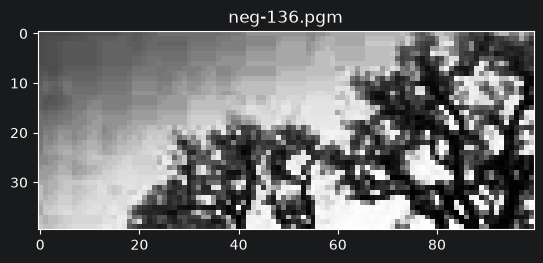

In [21]:
i=4

#todo: show test image with index i (as we did for the training images) 
plt.imshow(test_images[i], cmap='gray')
plt.title(test_image_names[i])
plt.show()

In [22]:
def resize_function(images):
    resized_list = []
    for img in images:
        resized_list.append(np.resize(img,(40,100)))
    return resized_list

# todo: make 1 big 3D array out of the images in the list.
# For this purpose first convert the images in the list to the same size with the resize_function
#test_images = ...
test_images = np.array(resize_function(test_images), dtype=np.float32)

# todo: print the dimensions of the array
print(test_images.shape)

(302, 40, 100)


### Standardize Test Set

Finally, we have loaded our training images. Now we also need to standardize them (as we did for the training set).

**VERY IMPORTANT:** the test data has to be standardized <b>in the same way</b> as the training data for compatibility with the model! Because the test set may have a slightly different distribution. 

That means, **we take the mean and standard deviation of the training data to standardize the test data**.

**NEVER use the mean and standard deviation of the test data to standardize the test data!**

In [23]:
#todo: standardize the test images (as we did for the training set)

#test_images = ...
test_images = (test_images - mean) / stddev

### Flatten the Test Images

In [24]:
# Now flatten the test images, as we did for the training set. 
# The flattened matrix should have as many rows as test images and again
# 4000 columns (the number of pixels)


test_images_flat = test_images.reshape(test_images.shape[0], -1)

# print the dimensions:
print(test_images_flat.shape)

(302, 4000)


### Make Predictions

Now, we are ready to test our trained model on the test data. Use again the function model.predict_classes() but this thime pass the flattened test images instead of the training images. store the result in a variable  test_pred. **Note:** Depending on your tensorflow version you might have to use (model.predict(images_flat) > 0.5).astype("int32") instead of model.predict_classes(). 

In [25]:
# test_pred = ...
test_pred = (model.predict(test_images_flat) > 0.5).astype("int32")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


Now we have nice predictions. But are they correct? We do not know. To check this, we need to compare the predictions with the ground truth.

To load the ground truth for the test set, we need to extract the class labels again from the file names (as we did for the training set).

Go through all test files (i.e. all file names) in a loop and extract the first three characters of the filename. For negative samples "neg" assign the label 0 and for positive samples "pos" assign the label 1

In [26]:
# Load Groundtruth and create a label vector "test_classes":

test_classes = []

for name in test_image_names:
    if name.startswith('pos'):
        test_classes.append(1)
    else:
        test_classes.append(0)

Now we need to determine the accuracy of the test set.

To estimate this, we again call function accuracy_score(). This time we pass the label vector of the test images and the predictions of the test images.

In [27]:
#test_acc = ...
test_acc = accuracy_score(test_classes, test_pred)
print("Test accuracy:", test_acc)

Test accuracy: 0.5364238410596026


**Question:** How does the accuracy compare to the random baseline? Is the performace of this network any good? 

**Write your answer here:**

The random baseline is about 0.60 (550 out of 917 training samples are cars). Although the training accuracy reaches 100%, the MLP only achieves a test accuracy of roughly 0.55, i.e. at or even below the random baseline. The network therefore does not generalize: it has simply memorized the training set (overfitting). A fully connected network ignores the spatial structure of the image, so it cannot learn useful visual features here. This motivates the convolutional networks used in Lab B.

In the next lab we will see how we can further improve the performance by using convolutional neural networks.

# Lab B: Convolutional Neural Networks

A Convolutional Neural Network (ConvNet or CNN) is a type of (deep) Neural Network that is well-suited for 2D data, such as images, as it is optimized for learning from spatial proximity. Its core elements are 2D filter kernels which essentially learn the weights of the Neural Network, and downscaling functions such as Max Pooling.

A CNN can have one or more Convolution layers, each of them having an arbitrary number of N filters (which define the depth of the CNN layer), following typically by a pooling step, which groups neighboring pixels together and thus reduces the image resolution by retaining only the maximum values of neighboring pixels (downsampling).

## Exercise 1

### Input

Let's start with the input data for our first CNN. The input to the CNN is the standardized version of the original image array (remember: subtracting the mean and dividing by the stddev).

#### Adding the color channel

CNNs operate on two dimensional input directly. Actually they use even 3D input becasues color images have several color channels. If our images were color images they would have dimension: 40x1000x3 --> thus three dimensions. 

For CNNs, we need to add a dimension for the color channel to the data, even if we only habe grayscale images (40x1000x1). Thus 
<b>for greyscale images we need to add an extra dimension for compatibility with the CNN implementation.</b>

Note: In Tensorflow, the color channel is the <b>last</b> dimension in the image shape. 

For greyscale images, we add the number 1 as the depth of the additional dimension of the input shape (for RGB color images, the number of channels is 3).

Note: our images are currently stored in 3D arrays. These arrays are 3D because we have all images in one array, so the dimensions are: numImages x height x width. Now we need to transform this into a 4D image by adding a dimension for the channel. The new dimensions are: numImages x height x width x 1


In [28]:
n_channels = 1 # for grey-scale = 1; 3 for RGB

#todo reshape the 3D training image array (img_array) and the 3D test 
# image array (test_images) by appendin. Reshape the arrays and store 
# the result in the variables  below:

#train_img = ...
#test_img = ...

Finally, we have to define the input size of our CNN. This is similar as for the multi-layer preceptron from the last lab. Remember, there we set the input dimension simply to the number of pixels (4000). The input was thus one-dimensional.

A CNN takes 3 dimensional input, of the size:  height x width x numChannels

Store these three numbers in variable input_shape. You get these values easily by calling .shape() on the array train_img (do not hardcode them)

In [29]:
# input_shape = ...

## Create the CNN model

We are ready to define our first CNN! We will do this in a function because we will call this code several times in this and further labs and we do not want to copy and paste the whole definition all the time...

Use the function defined below for the model definition and follow the remarks below to define the model.


In [30]:
def createMyModel():
    
    #initialize a sequential model (as we did for the multi-layer preceptron)
    #model = ...
    
    # Layer 1:
    # ========
    
    # todo: add a convolutional filter to the model with:
    # - 16 filters of size 3x3
    # - set padding to 'valid'
    # - set the input shape according to the variable input_shape
    # Check the Keras documentation on convolutional filters (Conv2D):
    # https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D
    # ...
    
    # Layer 2:
    # ========
    # Next: for this exercise now add a "Rectified Linear Unit" activation function as a separate layer.
    # see: https://www.tensorflow.org/api_docs/python/tf/keras/layers/ReLU 
    # ...
    

    # Layer 3:
    # ========
    #Next: add a Max Pooling layer (MaxPooling2D) on top with size 2x2
    # ...
    
    # We are done with the first group of layers 
    
    
    # Layer 4
    # ========
    
    # todo: add a convolutional filter to the model with:
    # - 16 filters of size 3x3 (no further parameters needed, we use
    # defaults for them)
    # Note: we also do not have to pass an input_shape. This is only needed in the
    # first layer. For the second layer (here) the input_shape is automatically
    # set to the size of the output of Layer 1 (Keras does this for us)
    # ...
    
    # Layer 5:
    # ========
    
    #Add another ReLu Activation layer (as above)
    # ...
    

    # Flattening:
    # ===========
    # After having defined two convolutional layers (above) we want to put
    # a number of dense layers on top which generate the final classification
    # The output of the CNN layers are 3-dimensional feature maps 
    # (numFilters x featureMap height x featureMap width)
    # A fully connected (dense) layer needs 1-dimensional input. We add a 
    # "flatten-layer" to the network, to make a vector out of the feature map
    # of Layer 5. See https://www.tensorflow.org/api_docs/python/tf/keras/layers/Flatten
    # for more information on the 
    # flatten layer. The flatten layer does not need any parameters!
    # ...

    # First Dense Layer:
    # ==================
    # add a dense layer wth 256 neurons and relu as the activation funtion.
    # ...

    # Second Dense Layer:
    # ===================
    # add another dense layer wth 1 neuron as final output and specify "sigmoid" as activation function    
    # ...
    
    # The model definition is complete! Let's return the model

    return model

In [31]:
# Print the input shape and call the model definition (our function) and print a model summary:
print(input_shape)
model = createMyModel()
model.summary()

4000


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     1,024,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,090,307 (4.16 MB)

 Trainable params: 1,090,305 (4.16 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

**Question1:** Have a look at the printed model summary. Now compare the dimensions of input_shape with the dimensions of the output of the first convolutional layer. How do the settings in the first convolutional layer: 1. number of filters and 2. padding= 'valid' affect the output shape?

**Question2:** What is the effect of the max pooling layer (Layer 3) on the output shape?

**Write your answers here:**

### Training the CNN

Training our CNN is very similar to training the multi-layer perceptron. Most of what we need to know, we have already done in the last lab. Again call model.compile(...). Set the loss function to 'binary_crossentropy' and the optimizer to 'sgd'. The metric we want to use is again 'accuracy'

In [32]:
# Compile the model
...

Ellipsis

In [33]:
# Train the model
# again nothing new here. Use model.fit(...) (as before) to train the model.
# train for 7 epochs, use a batch size of 32. 

#...

<b>Again, our Accuracy rises quickly to almost 100%, with the CNN now even faster than with the Fully Connected Network.
Next, we evaluate how good our model performs on previously unseen data</b>

## Exercise 2

### Training with Validation Data

The likelihood that we have overfitting here is quite high. To detect overfitting during training we usually use a small set of the training data that we keep away from training and use only to check the generalization ability of the classifier. This set is called "validation set"

Note that this is similar to what we did before with the test set. Also in the case of the test set we take some data which was unseen in the training  to evaluate the generalization ability. But there are two important differences:
- First: the validation data is a small hold-out set from the *training* data. We leave the test set completele untouched. If we would use the test set now to evaluate and optimize our network, we would overfit on it. We should ALWAYS first optimize the network on the training data (and the validation data - which we cut off from the  training set) and when we found the best network parameters finally test on the test set.
- Second: the validation set is used for checking the generalization ability continuously DURING TRAINING. After each epoch we test with the validation set. The advantage of this is that we can detect overfitting: as long as the validation accuracy (which corresponds directly to the generalization ability) goes up during training, the network learns something useful. If the validation accuracy suddenly goes down or remains constant, we start to overfit. This means, we just learn and improve on the training data anymore but not on the validation data. This is the point where we should usually stop training!

Ok, long story short: let's train with a validation set:

We split off 20 % of the training data and use it as independend validation set to verify how good we are
on an independent data (not used for training) in each epoch

 

In [34]:
# recreate and recompile the model (otherwise we would continue learning)
# on the model trained before
#model = createMyModel()
#model.compile(...)

# Call model.fit(..) and add parameter "validation_split" with a value of 0.2 and save it as the variable "history"
# (which corresponds to 20%). Now 20% of the data are used for validation.
# on the remaining 80% the training is done
# ...

Keras outputs the validation accuracy as "val_acc". You can see how it changes during the training...

We can observe that the results on the split-off validation data are quite high (usually similar, but not as high as on the training data).

### Verifying Accuracy on Test Set

Although, we should not do this at this point (for the reasons mentioned above), we will have a look at how well our model performs on the test set (just for demonstration use)

Similarly, as already done for the multi-layer perceptron in Lab 11, evaluate the trained model on the test set

Call model.predict_classes() on the test images, print the results and call accuracy_score(...). Pass the predicted classes and the ground-truth classes to function accuracy_score().

In [35]:
#test_pred = ...

#compute accuracy...

**Question:** What accuracy do we get? Is it good? How does it compare to our random baseline?

**Write your answer here:**

### Plotting the Training Curve

The `model.fit` function returns a history including the evolution of training and validation loss and accuracy. We can plot it to see a nice training curve. 

This is the standard way to observe the training process. You will find such pictures in many papers.. 

In [36]:
# Use the following commands to get the training history

hist = history.history
print(hist.keys())
print(hist) # there are all the accuracies and loss estimates from all epochs in here!


dict_keys(['accuracy', 'loss'])
{'accuracy': [0.8102508187294006, 0.9618320465087891, 0.9825518131256104, 0.9912759065628052, 0.994547426700592, 0.9978189468383789, 0.9978189468383789, 0.9989094734191895, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'loss': [0.3954228460788727, 0.15078605711460114, 0.09503069519996643, 0.06720678508281708, 0.050636228173971176, 0.039647188037633896, 0.03220061585307121, 0.02666890248656273, 0.022580524906516075, 0.019449962303042412, 0.016953645274043083, 0.014973142184317112, 0.013353965245187283, 0.011998924426734447, 0.010890440084040165]}


Let's plot the data. 

First import matplotlib (if you have not done before) and then plot the infdividual curves. The code is provided below (you can use it as a template for the future)

In [37]:
# this will only work if you have matplotlib installed
import matplotlib.pyplot as plt

def plot_hist(hist,epochs):
    colors = {'loss':'r', 'accuracy':'b', 'val_loss':'m', 'val_accuracy':'g'}
    plt.figure(figsize=(10,6))
    plt.title("Training Curve") 
    plt.xlabel("Epoch")

    for measure in hist.keys():
        color = colors[measure]
        plt.plot(range(1,epochs+1), hist[measure], color + '-', label=measure)  # use last 2 values to draw line

    plt.legend(loc='upper left', scatterpoints = 1, frameon=False)
    plt.show()


In [38]:
plot_hist(hist,epochs)

NameError: name 'epochs' is not defined

**Question:** What is your overall conclusion from the curves and from the accuracy obtained on the test set?

**Write your answer here:**

We are done for now. More tuning of our network will be done later. There we will learn a number of things to make the network learn better. This Lab's goal was to show the very basics of how a CNN is defined and trained.

# Lab C: Improving your network!

In this lab, we will learn a number of methods that help to improve training efficiency, reduce overfitting and increase generalization ability. 

Part 3 and Part 4 of this lab are optional. Complete them for 4 extra points (2 each). 

The methods include
- Data augmentation
- Batch normalization
- Max Pooling
- Manipulating hyper parameters of the network

## Exercise 1

## I. Data Augmentation

have a look at our dataset. You will see that the images are all very similar with little variation. Thus, there is the risk that the network quickly overfitts on these patterns and will not be able to detect slight variations of it. This is where data augmentation can help.  

Data augmentation increases the training set by adding slightly transformed versions of the training images: Rotate, shift, flip and scale the original images to generate additional examples that will help the Neural Network to generalize better.

Define a data generator in Keras that specifies the transforms that shall be applied to the images:

use the function `ImageDataGenerator` and define the following transform:
- rotation_range of 20
- width shift range of 0.4
- height shift range of 0.4
- zoom range of 0.4
- horizontal flip

Read the Keras documentation to get familiar of what these functions do!


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#datagen = ...

# we set the random seed to 0 to enable repeatable results 
# (there is a lot of randomization in data augmentation)!
np.random.seed(0) 

#### Preparations for training

1. transform the pyhton lists which contain the training labels to a  numpy array ("classes"). Reason: ImageDataGenerator needs the classes as Numpy array instead of normal list 

2. take the training data (variable "train_img") and split it into two sets: a training set with 90% of the data and a validation set with 10% of the data. Reason: we need to do the splitting of training data into training set and validations set explicitly when we do data augmentation.

    Note 1: not only the train_img variable needs to be split but also variable "classes_array", so that we get label vectors for training and validation set.
    
    Note 2: both sets should contain equal proportions of samples from both sets (car / no car). Thus, we need a "stratified" split. You can do stratified splits with function `train_test_split()` from `sklearn.model_selection`. (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

3. Print the ground truth statistics for each set to make sure that the proportions of classes is equal in both sets



In [ ]:
#1. convert classes variable to numpy array
# classes_array = ...

#2. split training data into a training and validation set
#...

#3. Print the ground truth statistics for each set to make sure that 
# the proportions of classes is equal in both sets

We are ready for training now. Recreate the model (otherwise we would continue training on the already trained model from the last lab) and run `model.compile()`. Use a batch size of 32 again.

Use model `model.fit` again. This function can also use the previously defined data generator as input instead of the original training data. This means that whenever a training image is loaded from disk for training, it is transformed randomly. The network will never see the same image twice. At most variations of it!

Check the documentation of https://www.tensorflow.org/api_docs/python/tf/keras/Model

Many parameters (e.g. batch size, epochs) we know already

Some parameters are new: first we pass the datagenerator we have created (`datagen`). An new parameter is `steps_per_epoch`. This is the number of batches generated until an epoch is finished (remenber: an epoch means that all training images have been processed once). With data augmentation an epoch would never terminate because there are an arbitrary number of transforms of the input images possible. We set `steps_per_epoch` to number of training images / batch_size. This generates a similar behavior as before. 
The validation data is now added explicitly here to the generator (that was the reason why we needed to split it off from the remaining training data). Per default, the validation data is used as it is (no transforms are applied on validation images). But you can also add transforms to the validation set. For this you have to create a separate datagenerator for the validation set. If you like you can try it out. It makes usually improves the training and makes it more objective. 


In [ ]:
# todo: recreate and recompile the model (otherwise we continue learning)
# model = ...

batch_size = 32

# fits the model on batches with real-time data augmentation:
history = model.fit(datagen.flow(data_train, classes_train, batch_size=batch_size),
                    steps_per_epoch=data_train.shape[0]/batch_size, epochs=epochs,
                    validation_data=(data_val,classes_val)) 





### Verifying Accuracy on Test Set (with Data Augmentation)

Let's find out how well our network trained with augmentation does on the test set.

In [ ]:
#test_pred = ...
#accuracy = ...

### Plotting the Training and Validation Curves with Data Augmentation 

In [ ]:
# todo (as done in Lab B)

**Question:** How does the test accuracy you compare to the random baseline? Does the graph look better now? Can you detect overfitting from it? 

**Write your answer here:**

## Exercise 2 

## II. Dropout and Batch Normalization
Dropout and batch normalization are two methods to make a model generalize better. 

Dropout can be used on Dense and Conv2D layers and simply sets a proportion of feature map activations randomly to zero during learning. In this way the network can not overadapt (overfit) so easily. This results in a kind of regularization.

Batch normalization is applied after Conv2D or MaxPooling layers to normalize the activations (inputs) of a layer. For a whole minibatch the activations are first collected.  Then the mean is subtracted and a dividsion by the standard deviation is performed. This corresponds to a z-standardization of the activations. See e.g. https://en.wikipedia.org/wiki/Batch_normalization for a short introduction.

**Note: Use data augmentation on the training set for all further experiments!**

TODO: Create two novel functions by duplicating the function `createMyModel()` from Lab 12. Call one function `createMyModel_withDropout()` and one with `createMyModel_withBatchNorm()`.

For `createMyModel_withDropout()`:
- add a dropout layer (https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout) on top of layer 2 (after the ReLU activation) with a dropout portion of 0.3
- add a dropout layer after the first dense layer (again after the ReLU activation) with dropout portion of 0.1.
    
For `createMyModel_withBatchNorm()`:
- add a batch normalization layer (see https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization) after the Conv2D layer in Layer 1. Note: you do not need to pass any arguments to the batch normalization layer. We use only the defaults.
- add a batch normalization layer after the Conv2D layer in Layer 2 (again call it without parameters).

Train both networks (do not forget to compile both methods always before you train them and also use data augmentation again) and apply them to the test set. Plot the training curves.

Combine BatchNormalization and Dropout in an additional function: `createMyModel_withBatchNormAndDropout()` and evaluate it on the test set.

In [ ]:
# create model with dropout, compile and train
np.random.seed(0) # enforce repeatable and comparable results

# ...

In [ ]:
# create model with batch normalization, compile and train
np.random.seed(0) # enforce repeatable and comparable results
# ...

In [ ]:
# create model with batch normalization and dropout, compile and train
np.random.seed(0) # enforce repeatable and comparable results

# ...

**Question:** What is the effect of dropout and batch normalization on the performance of the network? Explain with the help of the plotted graphs.

**Write your answer here:**

## III. Tuning Hyperparameters (Optional)

There are a number of hyper parameters that we can adjust to improve the training. The most important are:
- learning rate
- decay
- batch size

III.1 Retrain the best model we had so far (i.e. the one with data augmentation) with different learning rates (e.g. 1, 0.1, 0.01)

III.2 Take the best found learning rate and change the decay (start with 1*10^-6 (=1e-6) then change to 1e-5 and 1e-7

III.3 take the best combination of learning rate and decay and change the batch size. How do differently large batch sizes change the performance? Evaluate batch sizes of: 1, 4, 8, 16, 32, and 64


Note: the learning rate and the decay can be adjusted in the optimizer, see: https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Optimizer. To adjust these value: do not pass the optimizer (formerly simply the string "sgd" to model.compile. Instead create an optimizer object as described in the link above and set the learning rate (lr) and the decay (decay) manually.

In [ ]:
# III.1 ...

In [ ]:
# III.2 ...

In [ ]:
# III.3 ...

## IV. Write your own CNN (Optional)

Now we have all necessary knowledge to create our own network. Take the CNN we have used so far as a starting point and create your own network. Add/remove layers, change the activation functions, extend the data augmentation, and try to beat the CNNs we have evaluated so far.

You may try to change the following to see the impact on the result:
- number of filters in conv2D layers
- filter kernel size (e.g. 3 x 3, 5 x 5, 7x7 ...)
- adding/not adding Batch Normalization
- adding/not adding ReLU Activation
- adding/not adding Max Pooling
- changing Pooling size (e.g. 1 x 2, 2 x 2, 2 x 1, or more)
- adding/changing/removing Dropout
- add additional transformations in data augmentation
- train for more epochs

Who gets the highest performance on the test set? (Note that this highly fosters overfitting on the test set, but we will still do it for the fun of it..)

In [ ]:
# Your CNN goes here
